<a href="https://colab.research.google.com/github/23070075-creator/NNDL-Lab/blob/main/Prcatical_10_NNDLipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import os
import io
import zipfile
import pickle
import urllib.request
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from scipy import sparse
from sklearn.preprocessing import normalize

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

try:
    request = urllib.request.Request(
        DATA_URL, headers={"User-Agent": "Mozilla/5.0"}
    )
    raw = urllib.request.urlopen(request, timeout=180).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as archive:
        name = next(n for n in archive.namelist() if n.endswith(".xlsx"))
        df = pd.read_excel(io.BytesIO(archive.read(name)))
except Exception as e:
    print("Automatic download failed:", e)
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    if filename.endswith(".csv"):
        df = pd.read_csv(filename, encoding="ISO-8859-1")
    else:
        df = pd.read_excel(filename)

df.columns = [str(c).strip() for c in df.columns]
df = df.rename(columns={
    "Customer ID": "CustomerID",
    "Invoice": "InvoiceNo",
    "Price": "UnitPrice"
})

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:

df = df.dropna(subset=["CustomerID", "StockCode", "InvoiceNo"])
df["CustomerID"] = df["CustomerID"].astype(int)
df["StockCode"] = df["StockCode"].astype(str).str.strip()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

df = df[~df["InvoiceNo"].str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

description_map = (
    df.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda s: s.value_counts().index[0])
    .to_dict()
)

inter = (
    df.groupby(["CustomerID", "StockCode"])
    .agg(
        last_ts=("InvoiceDate", "max"),
        quantity=("Quantity", "sum"),
        orders=("InvoiceNo", "nunique")
    )
    .reset_index()
)

def k_core(data, min_user=5, min_item=5):
    data = data.copy()
    while True:
        old_len = len(data)
        item_counts = data["StockCode"].value_counts()
        data = data[data["StockCode"].map(item_counts) >= min_item]

        user_counts = data["CustomerID"].value_counts()
        data = data[data["CustomerID"].map(user_counts) >= min_user]

        if len(data) == old_len:
            return data.reset_index(drop=True)

inter = k_core(inter)

inter["user"], user_ids = pd.factorize(inter["CustomerID"])
inter["item"], item_ids = pd.factorize(inter["StockCode"])

user_ids = np.asarray(user_ids)
item_ids = np.asarray(item_ids)
n_users = len(user_ids)
n_items = len(item_ids)

item_names = np.array([
    description_map.get(code, str(code)) for code in item_ids
])

user2idx = {u: i for i, u in enumerate(user_ids)}
item2idx = {i: j for j, i in enumerate(item_ids)}

print("Customers:", n_users)
print("Products:", n_items)
print("Interactions:", len(inter))

Customers: 4078
Products: 3149
Interactions: 265075


In [3]:

inter = inter.sort_values(["user", "last_ts"]).reset_index(drop=True)
inter["position"] = inter.groupby("user").cumcount(ascending=False)

train_df = inter[inter["position"] >= 2].copy()
val_df = inter[inter["position"] == 1].copy()
test_df = inter[inter["position"] == 0].copy()

def to_csr(data):
    return sparse.csr_matrix(
        (
            np.ones(len(data), dtype=np.float32),
            (data["user"], data["item"])
        ),
        shape=(n_users, n_items)
    )

R_train = to_csr(train_df)
R_val = to_csr(val_df)
R_test = to_csr(test_df)
R_train_val = R_train + R_val
R_all = R_train + R_val + R_test

val_targets = val_df.sort_values("user")["item"].to_numpy()
test_targets = test_df.sort_values("user")["item"].to_numpy()

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 256919
Validation: 4078
Testing: 4078


In [4]:

def sample_candidates(targets, excluded, seed=42, n_neg=99):
    rng = np.random.default_rng(seed)
    candidates = np.zeros((n_users, n_neg + 1), dtype=np.int32)
    candidates[:, 0] = targets
    all_items = np.arange(n_items)

    for u in range(n_users):
        seen = excluded.indices[
            excluded.indptr[u]:excluded.indptr[u + 1]
        ]
        pool = np.setdiff1d(all_items, seen)
        pool = pool[pool != targets[u]]

        if len(pool) < n_neg:
            raise ValueError("Not enough negative candidates.")

        candidates[u, 1:] = rng.choice(pool, n_neg, replace=False)

    return candidates

val_candidates = sample_candidates(val_targets, R_train, seed=1)
test_candidates = sample_candidates(test_targets, R_train_val, seed=2)

def ranking_metrics(ranks):
    hit = ranks < 10
    return {
        "HR@10": hit.mean(),
        "NDCG@10": (hit / np.log2(ranks + 2)).mean(),
        "MRR": (1 / (ranks + 1)).mean()
    }

def evaluate(score_fn, candidates):
    ranks = []

    for start in range(0, n_users, 512):
        end = min(start + 512, n_users)
        users = np.arange(start, end)
        items = candidates[start:end]
        scores = score_fn(users, items)

        target_scores = scores[:, 0:1]
        ranks.extend((scores > target_scores).sum(axis=1))

    return ranking_metrics(np.asarray(ranks))

In [5]:

popularity = np.asarray(R_train.sum(axis=0)).ravel()

def popularity_score(users, items):
    return popularity[items]

normalized = normalize(R_train.T.tocsr(), axis=1)
similarity = (normalized @ normalized.T).toarray().astype(np.float32)
np.fill_diagonal(similarity, 0)

knn_scores = np.asarray(R_train @ similarity)

def knn_score(users, items):
    return knn_scores[users[:, None], items]

baseline_results = {
    "Popularity": evaluate(popularity_score, test_candidates),
    "Item-KNN": evaluate(knn_score, test_candidates)
}

display(pd.DataFrame(baseline_results).T)

,HR@10,NDCG@10,MRR
Popularity,0.366111,0.21203,0.187279
Item-KNN,0.517165,0.34185,0.304053


In [6]:

def build_neumf(n_users, n_items):
    reg = regularizers.l2(1e-6)

    user = keras.Input(shape=(), dtype="int32", name="user")
    item = keras.Input(shape=(), dtype="int32", name="item")

    gmf_user = layers.Embedding(n_users, 32, embeddings_regularizer=reg)(user)
    gmf_item = layers.Embedding(n_items, 32, embeddings_regularizer=reg)(item)
    gmf = layers.Multiply()([gmf_user, gmf_item])
    gmf = layers.Flatten()(gmf)

    mlp_user = layers.Embedding(n_users, 32, embeddings_regularizer=reg)(user)
    mlp_item = layers.Embedding(n_items, 32, embeddings_regularizer=reg)(item)

    x = layers.Concatenate()([
        layers.Flatten()(mlp_user),
        layers.Flatten()(mlp_item)
    ])

    for units in [64, 32, 16]:
        x = layers.Dense(units, activation="relu")(x)
        x = layers.Dropout(0.2)(x)

    x = layers.Concatenate()([gmf, x])
    output = layers.Dense(1, activation="sigmoid")(x)

    return keras.Model([user, item], output)

model = build_neumf(n_users, n_items)

model.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="binary_crossentropy"
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ item (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 32)        │    130,496 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 32)        │    100,768 │ item[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 32)        │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 32)        │          0 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ flatten_1[0][0],  │
│ (Concatenate)       │                   │            │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 32)        │    130,496 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 32)        │    100,768 │ item[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 32)        │          0 │ embedding[0][0],  │
│                     │                   │            │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16)        │        528 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 32)        │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 16)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 48)        │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         49 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 469,345 (1.79 MB)

 Trainable params: 469,345 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1: loss=0.4485, HR@10=0.3923, NDCG@10=0.2135
Epoch 2: loss=0.4117, HR@10=0.4519, NDCG@10=0.2545
Epoch 3: loss=0.3787, HR@10=0.5115, NDCG@10=0.2966
Epoch 4: loss=0.3543, HR@10=0.5444, NDCG@10=0.3302
Epoch 5: loss=0.3353, HR@10=0.5645, NDCG@10=0.3482
Epoch 6: loss=0.3206, HR@10=0.5802, NDCG@10=0.3601
Epoch 7: loss=0.3069, HR@10=0.5880, NDCG@10=0.3654
Epoch 8: loss=0.2968, HR@10=0.5971, NDCG@10=0.3728
Epoch 9: loss=0.2872, HR@10=0.6045, NDCG@10=0.3766
Epoch 10: loss=0.2789, HR@10=0.6072, NDCG@10=0.3804
Epoch 11: loss=0.2719, HR@10=0.6069, NDCG@10=0.3789
Epoch 12: loss=0.2668, HR@10=0.6032, NDCG@10=0.3776
Epoch 13: loss=0.2620, HR@10=0.5996, NDCG@10=0.3750
Epoch 14: loss=0.2577, HR@10=0.6003, NDCG@10=0.3758
Epoch 15: loss=0.2543, HR@10=0.6020, NDCG@10=0.3749
Early stopping.


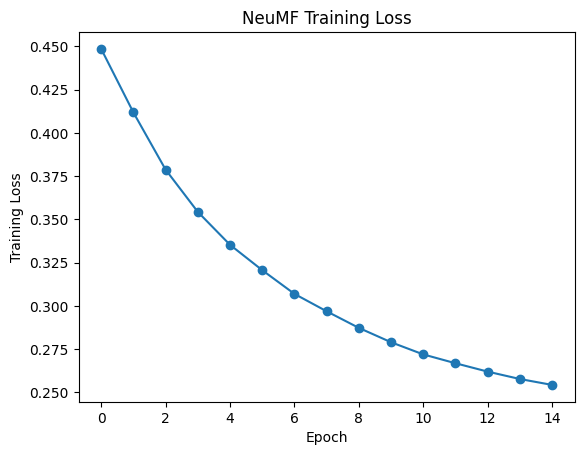

In [7]:

train_users = train_df["user"].to_numpy(dtype=np.int32)
train_items = train_df["item"].to_numpy(dtype=np.int32)

positive_pairs = set(
    (train_users.astype(np.int64) * n_items + train_items).tolist()
)

rng = np.random.default_rng(SEED)

def sample_training_data(n_neg=4):
    neg_users = np.repeat(train_users, n_neg)
    neg_items = rng.integers(0, n_items, len(neg_users))

    keys = neg_users.astype(np.int64) * n_items + neg_items
    bad = np.array([k in positive_pairs for k in keys])

    while bad.any():
        neg_items[bad] = rng.integers(0, n_items, bad.sum())
        keys = neg_users.astype(np.int64) * n_items + neg_items
        bad = np.array([k in positive_pairs for k in keys])

    users = np.concatenate([train_users, neg_users])
    items = np.concatenate([train_items, neg_items])
    labels = np.concatenate([
        np.ones(len(train_users)),
        np.zeros(len(neg_users))
    ]).astype(np.float32)

    order = rng.permutation(len(users))
    return users[order], items[order], labels[order]

def model_score(users, items):
    users = np.asarray(users, dtype=np.int32)
    items = np.asarray(items, dtype=np.int32)

    if items.ndim == 1:
        items = items.reshape(1, -1)

    b, m = items.shape

    predictions = model.predict(
        {
            "user": np.repeat(users, m),
            "item": items.reshape(-1)
        },
        batch_size=65536,
        verbose=0
    )

    return predictions.reshape(b, m)

best_score = -1
best_weights = None
wait = 0
patience = 5
history = []

for epoch in range(40):
    U, I, y = sample_training_data(4)

    result = model.fit(
        {"user": U, "item": I},
        y,
        batch_size=2048,
        epochs=1,
        verbose=0
    )

    val_metrics = evaluate(model_score, val_candidates)
    history.append(result.history["loss"][0])

    print(
        f"Epoch {epoch+1}: loss={history[-1]:.4f}, "
        f"HR@10={val_metrics['HR@10']:.4f}, "
        f"NDCG@10={val_metrics['NDCG@10']:.4f}"
    )

    if val_metrics["NDCG@10"] > best_score:
        best_score = val_metrics["NDCG@10"]
        best_weights = model.get_weights()
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print("Early stopping.")
        break

model.set_weights(best_weights)

plt.plot(history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("NeuMF Training Loss")
plt.show()

Test metrics:


,HR@10,NDCG@10,MRR
Popularity,0.3661,0.2120,0.1873
Item-KNN,0.5172,0.3419,0.3041
NeuMF,0.5517,0.3397,0.2933


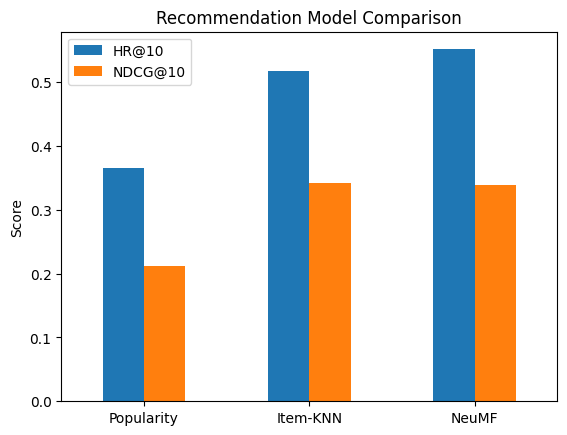

In [8]:

baseline_results["NeuMF"] = evaluate(model_score, test_candidates)

results = pd.DataFrame(baseline_results).T
print("Test metrics:")
display(results.round(4))

results[["HR@10", "NDCG@10"]].plot(kind="bar")
plt.title("Recommendation Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

In [9]:

def purchase_history(customer_id, limit=10):
    u = user2idx[customer_id]
    history = inter[inter["user"] == u].sort_values(
        "quantity", ascending=False
    ).head(limit)

    return pd.DataFrame({
        "Product Code": item_ids[history["item"].to_numpy()],
        "Product": item_names[history["item"].to_numpy()],
        "Quantity": history["quantity"].to_numpy()
    })

def recommend(customer_id, top_n=10):
    u = user2idx[customer_id]
    items = np.arange(n_items)
    users = np.full(n_items, u)

    scores = model.predict(
        {"user": users, "item": items},
        batch_size=4096,
        verbose=0
    ).flatten()

    scores[R_all[u].indices] = -np.inf
    top = np.argsort(-scores)[:top_n]

    return pd.DataFrame({
        "Rank": np.arange(1, len(top) + 1),
        "Product Code": item_ids[top],
        "Product": item_names[top],
        "Predicted Score": scores[top].round(4)
    })

customer_id = int(user_ids[0])

print("Purchase history:")
display(purchase_history(customer_id))

print("Top-10 recommendations:")
display(recommend(customer_id))

Purchase history:


,Product Code,Product,Quantity
0,23076,ICE CREAM SUNDAE LIP GLOSS,240
1,84558A,3D DOG PICTURE PLAYING CARDS,126
2,22492,MINI PAINT SET VINTAGE,108
3,23084,RABBIT NIGHT LIGHT,84
4,22196,SMALL HEART MEASURING SPOONS,72
5,84991,60 TEATIME FAIRY CAKE CASES,72
6,84992,72 SWEETHEART FAIRY CAKE CASES,72
7,21731,RED TOADSTOOL LED NIGHT LIGHT,72
8,21975,PACK OF 60 DINOSAUR CAKE CASES,48
9,22417,PACK OF 60 SPACEBOY CAKE CASES,48


Top-10 recommendations:


,Rank,Product Code,Product,Predicted Score
0,1,22629,SPACEBOY LUNCH BOX,0.9724
1,2,22630,DOLLY GIRL LUNCH BOX,0.9562
2,3,22326,ROUND SNACK BOXES SET OF4 WOODLAND,0.9181
3,4,23159,SET OF 5 PANCAKE DAY MAGNETS,0.9178
4,5,22631,CIRCUS PARADE LUNCH BOX,0.9148
5,6,23156,SET OF 5 MINI GROCERY MAGNETS,0.9089
6,7,23052,RECYCLED ACAPULCO MAT TURQUOISE,0.9002
7,8,23176,ABC TREASURE BOOK BOX,0.8879
8,9,22367,CHILDRENS APRON SPACEBOY DESIGN,0.8786
9,10,84692,BOX OF 24 COCKTAIL PARASOLS,0.8771


In [10]:

gmf_embeddings = model.layers[2].get_weights()[0]
mlp_embeddings = model.layers[4].get_weights()[0]

item_embeddings = np.concatenate(
    [gmf_embeddings, mlp_embeddings], axis=1
)

item_embeddings /= np.maximum(
    np.linalg.norm(item_embeddings, axis=1, keepdims=True),
    1e-12
)

def similar_products(product_code, top_n=8):
    idx = item2idx[product_code]
    scores = item_embeddings @ item_embeddings[idx]
    scores[idx] = -np.inf
    top = np.argsort(-scores)[:top_n]

    return pd.DataFrame({
        "Product Code": item_ids[top],
        "Product": item_names[top],
        "Similarity": scores[top].round(4)
    })

popular_code = item_ids[int(np.argmax(popularity))]
display(similar_products(popular_code))

model.save("/content/neumf_recommender.keras")

with open("/content/recsys_artifacts.pkl", "wb") as f:
    pickle.dump({
        "user_ids": user_ids,
        "item_ids": item_ids,
        "item_names": item_names
    }, f)

print("Model and mappings saved successfully.")

IndexError: list index out of range

In [11]:

gmf_embeddings = model.get_layer("gmf_item_embedding").get_weights()[0]
mlp_embeddings = model.get_layer("mlp_item_embedding").get_weights()[0]

item_embeddings = np.concatenate(
    [gmf_embeddings, mlp_embeddings], axis=1
)

print("Item embeddings shape:", item_embeddings.shape)

ValueError: No such layer: gmf_item_embedding. Existing layers are: ['user', 'item', 'embedding_2', 'embedding_3', 'flatten_1', 'flatten_2', 'concatenate', 'dense', 'dropout', 'dense_1', 'embedding', 'embedding_1', 'dropout_1', 'multiply', 'dense_2', 'flatten', 'dropout_2', 'concatenate_1', 'dense_3'].

In [12]:

for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__)

0 user InputLayer
1 item InputLayer
2 embedding_2 Embedding
3 embedding_3 Embedding
4 flatten_1 Flatten
5 flatten_2 Flatten
6 concatenate Concatenate
7 dense Dense
8 dropout Dropout
9 dense_1 Dense
10 embedding Embedding
11 embedding_1 Embedding
12 dropout_1 Dropout
13 multiply Multiply
14 dense_2 Dense
15 flatten Flatten
16 dropout_2 Dropout
17 concatenate_1 Concatenate
18 dense_3 Dense


In [13]:

for layer in model.layers:
    if "embedding" in layer.name.lower():
        weights = layer.get_weights()
        if weights:
            print(layer.name, weights[0].shape)

embedding_2 (4078, 32)
embedding_3 (3149, 32)
embedding (4078, 32)
embedding_1 (3149, 32)


In [14]:

gmf_embeddings = model.get_layer("embedding_3").get_weights()[0]
mlp_embeddings = model.get_layer("embedding_1").get_weights()[0]

item_embeddings = np.concatenate(
    [gmf_embeddings, mlp_embeddings], axis=1
)

print("Item embeddings shape:", item_embeddings.shape)

Item embeddings shape: (3149, 64)


In [15]:

for layer in model.layers:
    if "embedding" in layer.name.lower():
        print(layer.name, layer.input)

embedding_2 <KerasTensor shape=(None,), dtype=int32, sparse=False, ragged=False, name=user>
embedding_3 <KerasTensor shape=(None,), dtype=int32, sparse=False, ragged=False, name=item>
embedding <KerasTensor shape=(None,), dtype=int32, sparse=False, ragged=False, name=user>
embedding_1 <KerasTensor shape=(None,), dtype=int32, sparse=False, ragged=False, name=item>
